**Part B - Extensive margin: mode choice**

In [1]:
#packages 
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
df = pd.read_csv("parking_data_clean.csv")
ta = pd.read_csv("transit_access.csv")

df = (df.drop(columns=["transit_group", "transit_score"], errors="ignore")
        .merge(ta[["home_commune", "site", "transit_score", "transit_group"]],
               on=["home_commune", "site"], how="left", validate="m:1"))

1. Cross-tabulate main_mode by site and year. Report the gross flows in both directions
(the amount of people switching from car to another mode, and the opposite) and the net
mode share percentage change.

**Required output**: Table B1 with mode shares by site and year and the numbers switch-
ing car-to-non-car and non-car-to-car

In [2]:
# Cross-tabulate main_mode by year and site
pd.crosstab(
    index=[df["year"], df["site"]],
    columns=df["main_mode"]
)

main_mode      bike  bus  car
year site                    
2024 Lausanne    97  272  431
     Sion        29   54  117
2025 Lausanne   118  331  351
     Sion        29   48  123

In [3]:
# sort, and keep a clean 0..n-1 index so nothing downstream depends on the old order
df = df.sort_values(["employee_id", "year"]).reset_index(drop=True)

# previous-year values within each employee
g = df.groupby("employee_id")
previous_mode = g["main_mode"].shift(1)
previous_year = g["year"].shift(1)

# only compare consecutive years (all 2024 rows are False)
valid = df["year"] == previous_year + 1

# masks for the two directions
leave = valid & (previous_mode == "car") & (df["main_mode"] != "car")
join  = valid & (previous_mode != "car") & (df["main_mode"] == "car")

# gross flows
car_to_other = df[leave].groupby(["year", "site"]).size().rename("car_to_other")
other_to_car = df[join].groupby(["year", "site"]).size().rename("other_to_car")

# where the leavers go: car_to_bus, car_to_bike
destination = (df[leave]
               .groupby(["year", "site", "main_mode"]).size()
               .unstack(fill_value=0)
               .add_prefix("car_to_"))

# combine
gross_flows = (pd.concat([car_to_other, destination, other_to_car], axis=1)
                 .fillna(0).astype(int))
gross_flows["net_car_users"] = gross_flows["other_to_car"] - gross_flows["car_to_other"]
print(gross_flows)

# checks
counts = pd.crosstab([df["site"], df["year"]], df["main_mode"])
chg = counts.xs(2025, level="year")["car"] - counts.xs(2024, level="year")["car"]
assert (gross_flows.droplevel("year")["net_car_users"] == chg).all()      # flows reproduce the aggregate change
assert (gross_flows["car_to_bus"] + gross_flows["car_to_bike"]
        == gross_flows["car_to_other"]).all()                             # split adds up

               car_to_other  car_to_bike  car_to_bus  other_to_car  \
year site                                                            
2025 Lausanne            80           21          59             0   
     Sion                 0            0           0             6   

               net_car_users  
year site                     
2025 Lausanne            -80  
     Sion                  6  


In [4]:
# mdoe shares by year and site
shares = counts.div(counts.sum(axis=1), axis=0) * 100
print(shares.round(1))

main_mode      bike   bus   car
site     year                  
Lausanne 2024  12.1  34.0  53.9
         2025  14.8  41.4  43.9
Sion     2024  14.5  27.0  58.5
         2025  14.5  24.0  61.5


**TABLE B1 FINAL**

In [5]:
# net change in shares both percent and percentage points
s24 = shares.xs(2024, level="year")
s25 = shares.xs(2025, level="year")
net_pp  = s25 - s24
net_rel = 100 * (s25 - s24) / s24

net = pd.concat(
    {"Change (pp)": net_pp, "Change (% of 2024 share)": net_rel},
    axis=1
).round(1)

print(net)

          Change (pp)            Change (% of 2024 share)            
main_mode        bike  bus   car                     bike   bus   car
site                                                                 
Lausanne          2.6  7.4 -10.0                     21.6  21.7 -18.6
Sion              0.0 -3.0   3.0                      0.0 -11.1   5.1


In [6]:
# Nice table for the reportttt
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["STIXGeneral", "DejaVu Serif"]

def booktabs(t, title, fname, col_w=1.9, label_w=3.2, row_h=0.38,
             header_h=None, header_fs=10, body_fs=11, rule_after=()):
    """col_w can be one number or a list with one width per column."""
    n_rows, n_cols = t.shape
    widths = [col_w] * n_cols if np.isscalar(col_w) else list(col_w)
    xs = label_w + np.concatenate([[0], np.cumsum(widths)])   # column edges
    width = xs[-1]
    header_h = header_h or row_h
    height = header_h + row_h * n_rows + 0.9

    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_xlim(0, width); ax.set_ylim(0, height); ax.axis("off")

    top = height - 0.6
    body_top = top - header_h
    bottom = body_top - row_h * n_rows

    # header
    for j, c in enumerate(t.columns):
        ax.text((xs[j] + xs[j + 1]) / 2, top - header_h / 2, c,
                ha="center", va="center", weight="bold",
                fontsize=header_fs, linespacing=1.1)

    # body
    for i, (lab, row) in enumerate(t.iterrows()):
        y = body_top - row_h * (i + 0.5)
        ax.text(0.1, y, lab, ha="left", va="center", fontsize=body_fs)
        for j, v in enumerate(row):
            ax.text((xs[j] + xs[j + 1]) / 2, y, str(v),
                    ha="center", va="center", fontsize=body_fs)

    # rules
    ax.hlines(top, 0, width, color="black", lw=1.6)
    ax.hlines(body_top, 0, width, color="black", lw=0.7)
    ax.hlines(bottom, 0, width, color="black", lw=1.6)
    for k in rule_after:                    # thin rule after data row k (1-based)
        ax.hlines(body_top - row_h * k, 0, width, color="black", lw=0.4)

    ax.text(width / 2, height - 0.2, title, ha="center", va="center",
            fontsize=12, weight="bold")
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

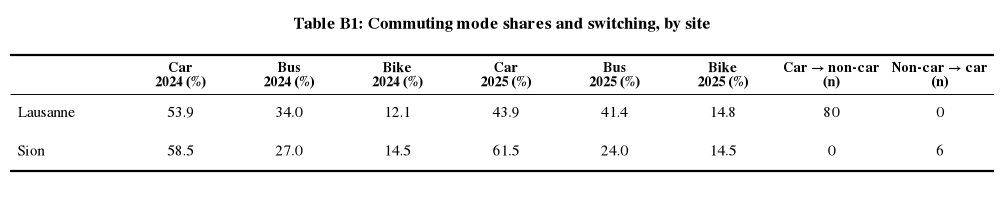

In [7]:
gf = gross_flows.droplevel("year")        # index = site

rows = {}
for site in ["Lausanne", "Sion"]:
    r = {}
    for y in [2024, 2025]:
        for m in ["car", "bus", "bike"]:
            r[f"{m.capitalize()}\n{y} (%)"] = f"{shares.loc[(site, y), m]:.1f}"
    r["Car → non-car\n(n)"] = f"{int(gf.loc[site, 'car_to_other'])}"
    r["Non-car → car\n(n)"] = f"{int(gf.loc[site, 'other_to_car'])}"
    rows[site] = r

B1 = pd.DataFrame(rows).T

booktabs(B1, "Table B1: Commuting mode shares and switching, by site",
         "table_B1.png", col_w=1.4, label_w=1.5, row_h=0.5)

**Comment**
In Lausanne, where the daily fee doubled, the car share fell from 53.9% to 43.9% (−10.0 pp, or −18.6%), while bus use rose from 34.0% to 41.4% and bike use from 12.1% to 14.8%. In Sion, where the fee was unchanged, the car share moved from 58.5% to 61.5% (+3.0 pp, +5.1%). The flows are one-directional: 80 Lausanne employees switched from car to another mode (59 to the bus, 21 to the bike) and none switched the other way, while in Sion 6 employees switched to the car and none left it. Gross and net flows therefore coincide, and all of the increase in bus and bike use in Lausanne comes from former drivers.

2. Compute the change in the car share in both percentage points and as an elasticity.
Explain why these answer different questions, and identify which measure belongs in the policy memo.

In [8]:
fee = df.groupby(["site", "year"])["parking_fee_chf"].first().unstack()

res = pd.DataFrame({
    "Car share 2024 (%)": s24["car"],
    "Car share 2025 (%)": s25["car"],
    "Change (pp)": s25["car"] - s24["car"],
})
res["Elasticity"] = (np.log(s25["car"] / s24["car"])
                     / np.log(fee[2025] / fee[2024])).replace([np.inf, -np.inf], np.nan)

print(res.round(2))

          Car share 2024 (%)  Car share 2025 (%)  Change (pp)  Elasticity
site                                                                     
Lausanne               53.87               43.88        -10.0        -0.3
Sion                   58.50               61.50          3.0         NaN


EXPLANATION:

**Percentage points vs. elasticity.** Between 2024 and 2025, the Lausanne car share fell from 53.9% to 43.9%, a change of −10.0 pp, while the daily fee doubled from CHF 2 to CHF 4. The implied elasticity is −0.30, computed as the log change in the car share divided by the log change in the fee. In Sion, where the fee did not change, the car share moved by +3.0 points and no elasticity can be computed.
The two measures answer different questions. The percentage-point change is an absolute quantity: it says how far the car share moved at this site, for this price increase. The elasticity is relative and unit-free: it relates the proportional fall in car use to the proportional rise in the fee. 

**For the memo.** The elasticity belongs in the memo > it can be compared across groups with different baseline shares and applied to a new price



3. Describe heterogeneity in these results: disaggregate the previous result by

• transit-accessibility group

• income tercile

• number of children

Define how groups are formed and report group sample sizes.

**Required output**: Table B2 with, for every requested group, 2024 and 2025 car shares,
the percentage-point change, extensive elasticity, and number of employees.

In [9]:
print("transit_group" in df.columns, "transit_score" in df.columns)


True True


In [10]:
# --- one row per employee, using 2024 characteristics for the groups ---
d24 = df[df["year"] == 2024].set_index("employee_id")
d25 = df[df["year"] == 2025].set_index("employee_id")

emp = pd.DataFrame({
    "site": d24["site"],
    "car24": d24["uses_car"],
    "car25": d25["uses_car"],
    "income24": d24["gross_income_chf"],
    "n_children": d24["n_children"],
    "transit_group": d24["transit_group"],
})

# --- form groups --- transit access/income tercile and children count
emp["transit_group"] = pd.Categorical(emp["transit_group"],
                                      categories=["Low", "Medium", "High"], ordered=True)
emp["income_tercile"] = pd.qcut(emp["income24"], 3, labels=["Low", "Middle", "High"])
emp["children_grp"] = emp["n_children"].map({0: "0", 1: "1", 2: "2+"})
emp["All"] = "All employees"

# --- checks and group sizes ---
print(emp[["income24", "transit_group", "children_grp"]].isna().sum())
print(emp["income24"].quantile([1/3, 2/3]))        # tercile cutoffs, for the methods text
for g in ["transit_group", "income_tercile", "children_grp"]:
    print(pd.crosstab(emp[g], emp["site"], margins=True), "\n")

# --- Table B2 (Lausanne, the only site where the fee changed) ---
def panel(gcol, label):
    L = emp[emp["site"] == "Lausanne"]
    t = L.groupby(gcol, observed=True).agg(s24=("car24", "mean"),
                                           s25=("car25", "mean"),
                                           N=("car24", "size"))
    out = pd.DataFrame({
        "Car share 2024 (%)": 100 * t["s24"],
        "Car share 2025 (%)": 100 * t["s25"],
        "Change (pp)": 100 * (t["s25"] - t["s24"]),
        "Elasticity": (np.log(t["s25"] / t["s24"]) / np.log(2)).replace([np.inf, -np.inf], np.nan),
        "N": t["N"],
    })
    out.index = pd.MultiIndex.from_product([[label], out.index.astype(str)])
    return out

B2 = pd.concat([panel("All", "Overall"),
                panel("transit_group", "Transit access"),
                panel("income_tercile", "Income tercile"),
                panel("children_grp", "Number of children")])
print(B2.round(2))

income24         4
transit_group    0
children_grp     0
dtype: int64
0.333333     77500.0
0.666667    103200.0
Name: income24, dtype: float64
site           Lausanne  Sion   All
transit_group                      
Low                 175   122   297
Medium              226    16   242
High                399    62   461
All                 800   200  1000 

site            Lausanne  Sion  All
income_tercile                     
Low                  253    80  333
Middle               261    71  332
High                 282    49  331
All                  796   200  996 

site          Lausanne  Sion   All
children_grp                      
0                  421   113   534
1                  155    29   184
2+                 224    58   282
All                800   200  1000 

                                  Car share 2024 (%)  Car share 2025 (%)  \
Overall            All employees               53.87               43.88   
Transit access     Low                         40.00     

**FINAL TABLE B2**

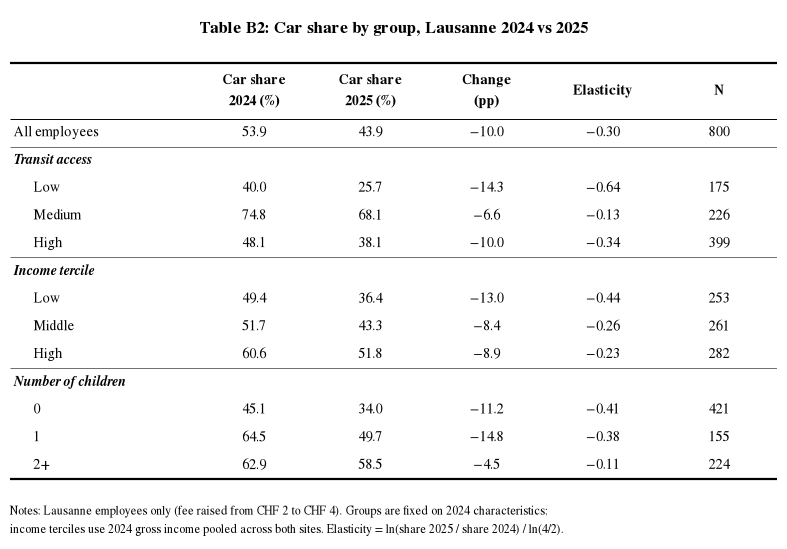

In [11]:
#nicer table for B2

import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "serif", "font.serif": ["STIXGeneral", "DejaVu Serif"]})

def fmt(v, col):
    if pd.isna(v):
        return "–"
    if col == "N":
        return f"{int(v)}"
    s = {"Elasticity": f"{v:.2f}", "Change (pp)": f"{v:+.1f}"}.get(col, f"{v:.1f}")
    return s.replace("-", "−")                      # proper minus sign

def booktabs_panels(B2, headers, title, note, fname, label_w=2.4, col_w=1.5, row_h=0.36):
    cols = list(B2.columns)
    rows = []                                       # (kind, label, formatted values)
    for p in dict.fromkeys(B2.index.get_level_values(0)):
        if p != "Overall":
            rows.append(("panel", p, None))
        for g, r in B2.loc[p].iterrows():
            rows.append(("overall" if p == "Overall" else "row", g,
                         [fmt(r[c], c) for c in cols]))

    n_hdr = 2 * row_h
    width = label_w + col_w * len(cols)
    height = n_hdr + row_h * len(rows) + 1.4
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_xlim(0, width); ax.set_ylim(0, height); ax.axis("off")
    top = height - 0.7
    xc = lambda j: label_w + col_w * (j + 0.5)      # x-centre of column j

    ax.text(width / 2, height - 0.25, title, ha="center", va="center",
            fontsize=12, weight="bold")
    for j, h in enumerate(headers):
        ax.text(xc(j), top - n_hdr / 2, h, ha="center", va="center",
                weight="bold", fontsize=10)
    ax.hlines(top, 0, width, color="black", lw=1.6)
    ax.hlines(top - n_hdr, 0, width, color="black", lw=0.7)

    y = top - n_hdr
    for k, (kind, label, vals) in enumerate(rows):
        yc = y - row_h / 2
        if kind == "panel":
            if k > 0:
                ax.hlines(y, 0, width, color="black", lw=0.4)     # thin separator
            ax.text(0.05, yc, label, ha="left", va="center",
                    fontsize=10, style="italic", weight="bold")
        else:
            ax.text(0.05 if kind == "overall" else 0.3, yc, label,
                    ha="left", va="center", fontsize=10)
            for j, v in enumerate(vals):
                ax.text(xc(j), yc, v, ha="center", va="center", fontsize=10)
        y -= row_h

    ax.hlines(y, 0, width, color="black", lw=1.6)
    ax.text(0, y - 0.3, note, ha="left", va="top", fontsize=8.5)
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

headers = ["Car share\n2024 (%)", "Car share\n2025 (%)", "Change\n(pp)", "Elasticity", "N"]
note = ("Notes: Lausanne employees only (fee raised from CHF 2 to CHF 4). Groups are fixed on 2024 characteristics;\n"
        "income terciles use 2024 gross income pooled across both sites. "
        "Elasticity = ln(share 2025 / share 2024) / ln(4/2).")

booktabs_panels(B2, headers, "Table B2: Car share by group, Lausanne 2024 vs 2025",
                note, "table_B2.png")

**Comment**

**Groups**: Transit-access groups (Low / Medium / High) come from the Part A index, assigned by commune and site. Income groups are terciles of 2024 gross annual income, pooled across both sites (cutoffs CHF 77,500 and CHF 103,200; N = 796 in Lausanne, as four employees have no income data). Children are grouped as 0, 1 and 2+. All groups are fixed on 2024 characteristics, and the table covers Lausanne, where the fee changed.

**Results**: Responses differ across groups. The lowest income tercile reduced car use most (−13.0 pp, elasticity −0.44), while the middle and upper terciles responded similarly (−8.4 and −8.9 pp; −0.26 and −0.23). Households with two or more children barely changed (−4.5 pp, −0.11) compared with households with no child (−11.2 pp, −0.41) or one child (−14.8 pp, −0.38). Concerning the Transit-access group, the Low group responded most (−14.3 pp, −0.64) and the Medium group least (−6.6 pp, −0.13). 

4. Estimate equation (1) sequentially:

(a) a Lausanne-only before–after or price specification;

(b) a specification adding Sion as a comparison site;

(c) the comparison specification with a justified set of controls, including transit accessibility; and

(d) a specification allowing the policy response to differ with transit accessibility, income, and number of children (interactions).

State how the variables entering the interactions are coded or grouped. You may, for example, mean-centre a continuous variable by subtracting its sample mean; in that case, the main policy coefficient represents the estimated response for an employee with average values of the centred characteristics. If you use categories instead, state the reference group. Interpret the interaction pattern and compare it with Table B2; a separate table of predicted group effects is optional.

**Required output**: Table B3, a single four-column regression table. Report policy variables, interaction terms, and other controls.

Limit the Sion comparison to one short paragraph. State what it contributes, how it changes the Lausanne-only result, and one reason for caution. Do not turn the report into an extended discussion of difference-in-differences.

In [12]:
# a) Lausanne-only before-after + Sion as comparison
import statsmodels.formula.api as smf

df["log_fee"] = np.log(df["parking_fee_chf"])
df["log_inc"] = np.log(df["gross_income_chf"])

# one estimation sample for every column
need = ["uses_car", "log_fee", "site", "year", "transit_score", "log_inc",
        "n_children", "distance_km", "age", "gender", "fte"]
d = df.dropna(subset=need).copy()

def fit(formula, data):
    # cluster by employee: each person appears in two years
    return smf.ols(formula, data).fit(cov_type="cluster",
                                      cov_kwds={"groups": data["employee_id"]})

m_a = fit("uses_car ~ log_fee", d[d["site"] == "Lausanne"])                # Lausanne before-after
m_b = fit("uses_car ~ log_fee + C(site) + C(year)", d)                     # + Sion as comparison

for name, m in [("a", m_a), ("b", m_b)]:
    b = m.params["log_fee"]
    print(name, "coef", round(b, 4), "SE", round(m.bse["log_fee"], 4),
          "-> doubling:", round(100 * b * np.log(2), 1), "pp")

a coef -0.145 SE 0.0154 -> doubling: -10.1 pp
b coef -0.1883 SE 0.0233 -> doubling: -13.1 pp


In [13]:
from statsmodels.iolib.summary2 import summary_col

# --- variables ---
inc10k = d["gross_income_chf"] / 10000
d["inc10k_c"] = inc10k - inc10k.mean()
d["score_c"]  = d["transit_score"] - d["transit_score"].mean()
d["kid1"] = (d["n_children"] == 1).astype(int)       # reference: 0 children
d["kid2"] = (d["n_children"] == 2).astype(int)       # 2 = "2 or more"
d["kid1_c"] = d["kid1"] - d["kid1"].mean()
d["kid2_c"] = d["kid2"] - d["kid2"].mean()

print(d[["transit_score", "distance_km", "gross_income_chf"]].corr().round(2))   # collinearity check

# --- columns (c) and (d) ---
ctrl = "score_c + inc10k_c + kid1 + kid2 + distance_km + age + C(gender) + fte"
m_c = fit(f"uses_car ~ log_fee + C(site) + C(year) + {ctrl}", d)
m_d = fit("uses_car ~ log_fee + log_fee:score_c + log_fee:inc10k_c"
          f" + log_fee:kid1_c + log_fee:kid2_c + C(site) + C(year) + {ctrl}", d)

# --- effect of doubling the fee, in pp (for (d): average employee) ---
for name, m in [("a", m_a), ("b", m_b), ("c", m_c), ("d", m_d)]:
    b, se = m.params["log_fee"], m.bse["log_fee"]
    print(name, f"doubling: {100*b*np.log(2):.1f} pp  (SE {100*se*np.log(2):.1f})")

tab = summary_col([m_a, m_b, m_c, m_d], stars=True,
                  model_names=["(a)", "(b)", "(c)", "(d)"],
                  info_dict={"N": lambda x: f"{int(x.nobs)}"}, float_format="%.3f")
print(tab)

                  transit_score  distance_km  gross_income_chf
transit_score              1.00         0.01              0.17
distance_km                0.01         1.00             -0.06
gross_income_chf           0.17        -0.06              1.00
a doubling: -10.1 pp  (SE 1.1)
b doubling: -13.1 pp  (SE 1.6)
c doubling: -13.1 pp  (SE 1.6)
d doubling: -12.6 pp  (SE 1.7)

                    (a)       (b)       (c)       (d)   
--------------------------------------------------------
Intercept        0.642***  0.672***  0.582***  0.601*** 
                 (0.023)   (0.026)   (0.151)   (0.152)  
log_fee          -0.145*** -0.188*** -0.188*** -0.182***
                 (0.015)   (0.023)   (0.023)   (0.025)  
C(site)[T.Sion]            0.044     0.086**   0.091**  
                           (0.039)   (0.042)   (0.043)  
C(year)[T.2025]            0.030**   0.030**   0.030**  
                           (0.012)   (0.012)   (0.012)  
C(gender)[T.M]                       -0.045*   -0.045

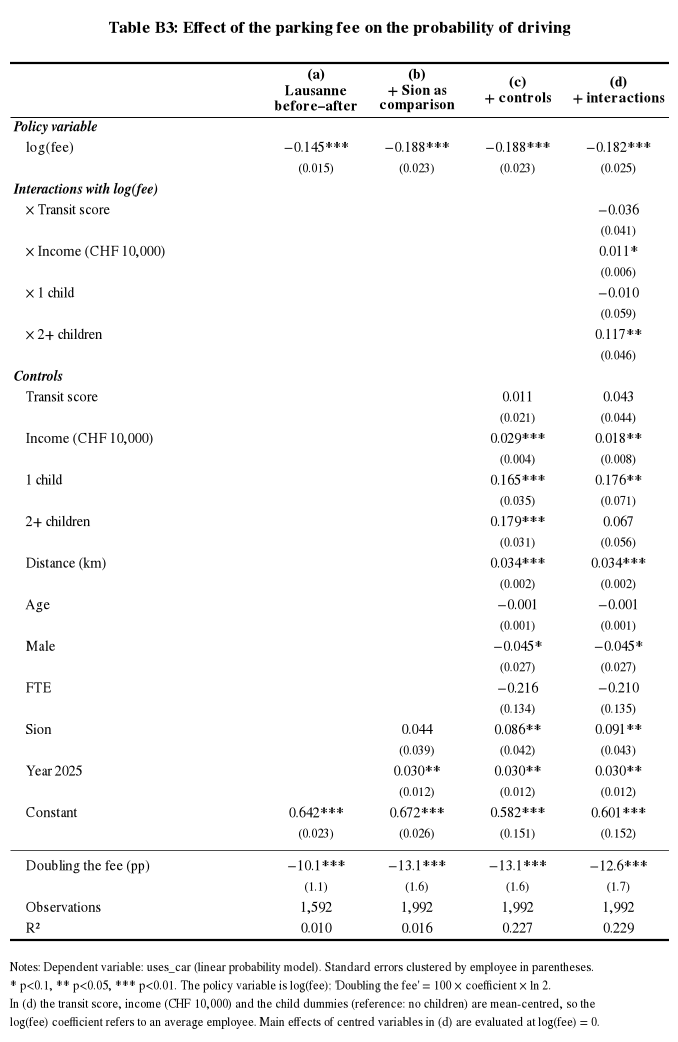

In [14]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "serif", "font.serif": ["STIXGeneral", "DejaVu Serif"]})
LN2 = np.log(2)
models = [m_a, m_b, m_c, m_d]

def stars(p):
    return "***" if p < .01 else "**" if p < .05 else "*" if p < .1 else ""

def cell(m, var):
    """coefficient with stars, and standard error in parentheses"""
    if var not in m.params.index:
        return "", ""
    b = f"{m.params[var]:.3f}{stars(m.pvalues[var])}"
    return b.replace("-", "−"), f"({m.bse[var]:.3f})"

sections = [
    ("Policy variable", [("log_fee", "log(fee)")]),
    ("Interactions with log(fee)", [
        ("log_fee:score_c", "× Transit score"),
        ("log_fee:inc10k_c", "× Income (CHF 10,000)"),
        ("log_fee:kid1_c", "× 1 child"),
        ("log_fee:kid2_c", "× 2+ children")]),
    ("Controls", [
        ("score_c", "Transit score"), ("inc10k_c", "Income (CHF 10,000)"),
        ("kid1", "1 child"), ("kid2", "2+ children"),
        ("distance_km", "Distance (km)"), ("age", "Age"),
        ("C(gender)[T.M]", "Male"), ("fte", "FTE"),
        ("C(site)[T.Sion]", "Sion"), ("C(year)[T.2025]", "Year 2025"),
        ("Intercept", "Constant")]),
]

def build_rows():
    rows = []
    for sec, items in sections:
        rows.append(("section", sec, None))
        for var, lab in items:
            c = [cell(m, var) for m in models]
            rows.append(("coef", lab, [x[0] for x in c]))
            rows.append(("se", "", [x[1] for x in c]))
    rows.append(("rule", None, None))
    # effect of doubling the fee, in percentage points
    dbl = [f"{100*m.params['log_fee']*LN2:.1f}{stars(m.pvalues['log_fee'])}".replace("-", "−")
           for m in models]
    dbl_se = [f"({100*m.bse['log_fee']*LN2:.1f})" for m in models]
    rows += [("coef", "Doubling the fee (pp)", dbl), ("se", "", dbl_se),
             ("stat", "Observations", [f"{int(m.nobs):,}" for m in models]),
             ("stat", "R²", [f"{m.rsquared:.3f}" for m in models])]
    return rows

def b3_table(fname, title, headers, note, label_w=3.3, col_w=1.3, row_h=0.27, header_h=0.7):
    rows = build_rows()
    h = lambda k: 0.15 if k == "rule" else row_h
    body_h = sum(h(k) for k, _, _ in rows)
    width = label_w + col_w * len(models)
    height = header_h + body_h + 1.7
    fig, ax = plt.subplots(figsize=(width, height))
    ax.set_xlim(0, width); ax.set_ylim(0, height); ax.axis("off")
    top = height - 0.7
    xc = lambda j: label_w + col_w * (j + 0.5)

    ax.text(width / 2, height - 0.25, title, ha="center", va="center", fontsize=12, weight="bold")
    for j, t in enumerate(headers):
        ax.text(xc(j), top - header_h / 2, t, ha="center", va="center",
                weight="bold", fontsize=10, linespacing=1.1)
    ax.hlines(top, 0, width, color="black", lw=1.6)
    ax.hlines(top - header_h, 0, width, color="black", lw=0.7)

    y = top - header_h
    for kind, label, vals in rows:
        if kind == "rule":
            ax.hlines(y - 0.07, 0, width, color="black", lw=0.5)
        else:
            yc = y - row_h / 2
            if kind == "section":
                ax.text(0.05, yc, label, ha="left", va="center", fontsize=10,
                        style="italic", weight="bold")
            else:
                ax.text(0.2, yc, label, ha="left", va="center", fontsize=10)
                for j, v in enumerate(vals):
                    ax.text(xc(j), yc, v, ha="center", va="center",
                            fontsize=9 if kind == "se" else 10)
        y -= h(kind)

    ax.hlines(y, 0, width, color="black", lw=1.6)
    ax.text(0, y - 0.25, note, ha="left", va="top", fontsize=8.5)
    plt.savefig(fname, dpi=300, bbox_inches="tight")
    plt.show()

headers = ["(a)\nLausanne\nbefore–after", "(b)\n+ Sion as\ncomparison", "(c)\n+ controls", "(d)\n+ interactions"]
note = ("Notes: Dependent variable: uses_car (linear probability model). Standard errors clustered by employee in parentheses.\n"
        "* p<0.1, ** p<0.05, *** p<0.01. The policy variable is log(fee); 'Doubling the fee' = 100 × coefficient × ln 2.\n"
        "In (d) the transit score, income (CHF 10,000) and the child dummies (reference: no children) are mean-centred, so the\n"
        "log(fee) coefficient refers to an average employee. Main effects of centred variables in (d) are evaluated at log(fee) = 0.")

b3_table("table_B3.png", "Table B3: Effect of the parking fee on the probability of driving", headers, note)

**Comment**

Column (a), the Lausanne-only comparison, implies that doubling the daily fee reduces the probability of driving by 10.1 percentage points. Adding Sion as a comparison site raises the estimate to 13.1 points (column b), because car use in Sion rose slightly in 2025 without any fee change. Adding controls leaves it unchanged (column c), and the average response in the interaction model is 12.6 points (column d). Responses differ by household composition: employees with two or more children respond about eight points less than those with no children (p<0.05), and the response weakens slightly with income (p<0.1), in line with the descriptive pattern in Table B2. The transit index shows no significant interaction.

**Other notes**
B1 and B2 give -10.0pp for Lausanne and column (a) of B3  gives -10.1 pp. The difference possibly comes from the sample: B3 drops 4 Lausanne employees with missing income in both 2024 and 2025. The same applis to the Sion-adjusted effect (-13.0 vs 13.1 pp).

**Sion comparison**
Adding Sion as a comparison site removes changes between 2024 and 2025 that are unrelated to the fee. Car use in Sion rose by about three percentage points although its fee stayed at CHF 2, so the Lausanne-only estimate understates the policy effect: doubling the fee lowers the probability of driving by 13.1 percentage points (column b), compared with 10.1 points in the Lausanne-only specification (column a).

The comparison assumes that car use in Lausanne would have moved like Sion’s without the fee increase; with only two years of data, this assumption cannot be checked.